In [1]:

# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")


All libraries imported successfully!


In [6]:

# Import the dataset from Scikit-learn

from sklearn.datasets import load_diabetes

# Load dataset
diabetes = load_diabetes()

# Convert dataset into a Pandas DataFrame
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)

# Add target column
df["target"] = diabetes.target

# Display first 5 rows
print("First 5 rows of the dataset:")
display(df.head())


First 5 rows of the dataset:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [7]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()


Dataset Shape: (442, 11)

Column Names:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6', 'target']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB


In [8]:

# Check missing values

print("Missing Values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df.duplicated().sum())

# Check dataset shape
print("\nDataset Shape:")
print(df.shape)


Missing Values:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Duplicate Records:
0

Dataset Shape:
(442, 11)


In [9]:

# Calculate correlation matrix

correlation_matrix = df.corr()

# Display correlation matrix

print("Correlation Matrix:")
display(correlation_matrix)


Correlation Matrix:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
age,1.000000,0.173737,0.185085,0.335428,0.260061,0.219243,-0.075181,0.203841,0.270774,0.301731,0.187889
sex,0.173737,1.000000,0.088161,0.241010,0.035277,0.142637,-0.379090,0.332115,0.149916,0.208133,0.043062
bmi,0.185085,0.088161,1.000000,0.395411,0.249777,0.261170,-0.366811,0.413807,0.446157,0.388680,0.586450
bp,0.335428,0.241010,0.395411,1.000000,0.242464,0.185548,-0.178762,0.257650,0.393480,0.390430,0.441482
s1,0.260061,0.035277,0.249777,0.242464,1.000000,0.896663,0.051519,0.542207,0.515503,0.325717,0.212022
s2,0.219243,0.142637,0.261170,0.185548,0.896663,1.000000,-0.196455,0.659817,0.318357,0.290600,0.174054
s3,-0.075181,-0.379090,-0.366811,-0.178762,0.051519,-0.196455,1.000000,-0.738493,-0.398577,-0.273697,-0.394789
s4,0.203841,0.332115,0.413807,0.257650,0.542207,0.659817,-0.738493,1.000000,0.617859,0.417212,0.430453
s5,0.270774,0.149916,0.446157,0.393480,0.515503,0.318357,-0.398577,0.617859,1.000000,0.464669,0.565883
s6,0.301731,0.208133,0.388680,0.390430,0.325717,0.290600,-0.273697,0.417212,0.464669,1.000000,0.382483


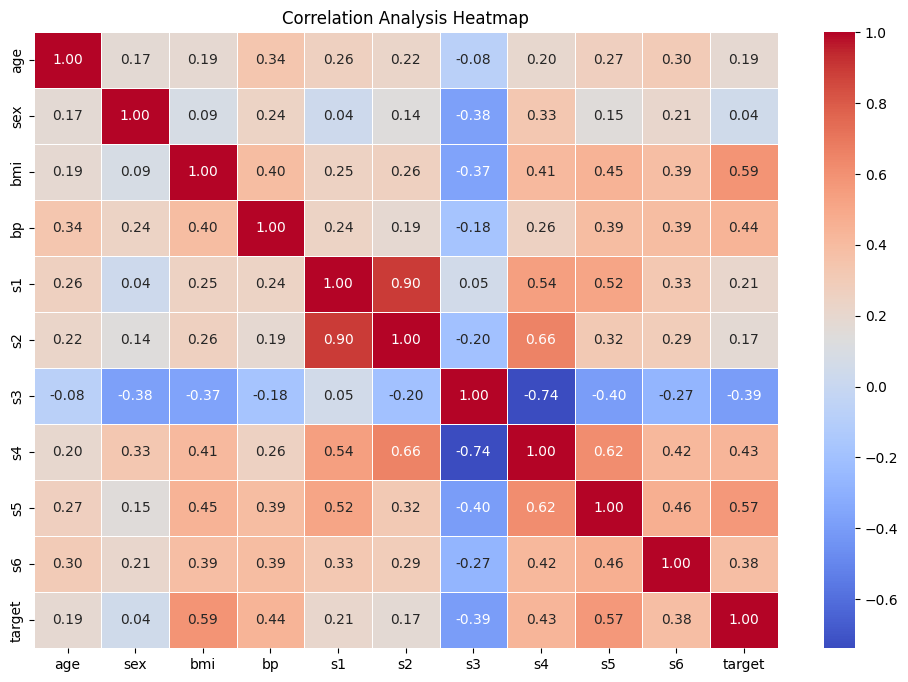

In [10]:

# Create correlation heatmap

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Analysis Heatmap")
plt.show()


In [11]:

# Find the strongest correlations

corr_pairs = correlation_matrix.unstack()

# Remove duplicate pairs and self-correlations
corr_pairs = corr_pairs[corr_pairs.index.get_level_values(0) <
                        corr_pairs.index.get_level_values(1)]

# Sort by absolute correlation value
strong_corr = corr_pairs.reindex(
    corr_pairs.abs().sort_values(ascending=False).index
)

print("Top 10 Strongest Correlations:")
display(strong_corr.head(10))


Top 10 Strongest Correlations:


s1   s2        0.896663
s3   s4       -0.738493
s2   s4        0.659817
s4   s5        0.617859
bmi  target    0.586450
s5   target    0.565883
s1   s4        0.542207
     s5        0.515503
s5   s6        0.464669
bmi  s5        0.446157
dtype: float64

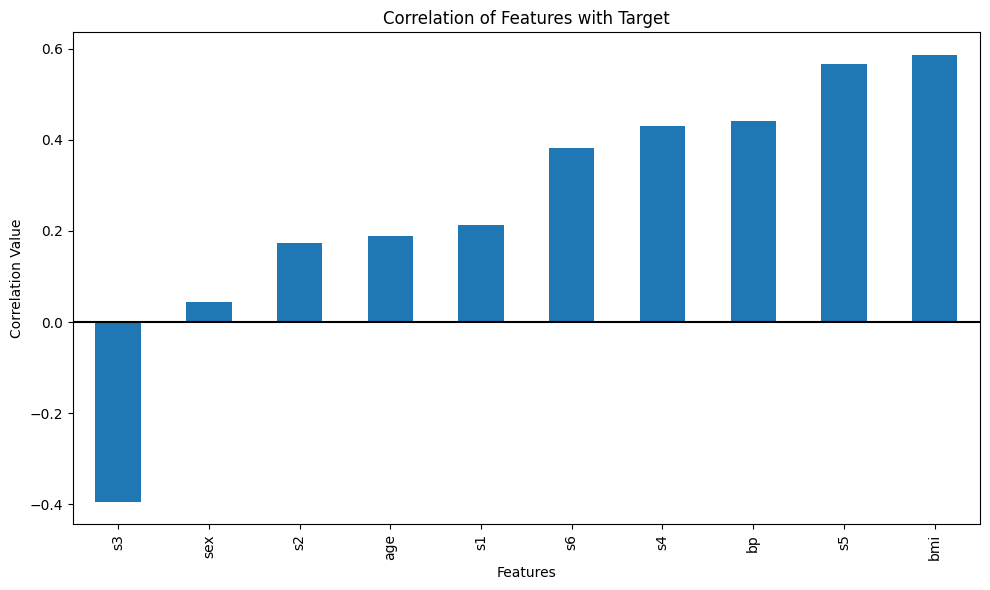

In [12]:

# Correlation of features with target

target_corr = correlation_matrix["target"].drop("target")

# Sort correlations
target_corr = target_corr.sort_values()

# Create bar chart
plt.figure(figsize=(10, 6))

target_corr.plot(kind="bar")

plt.title("Correlation of Features with Target")
plt.xlabel("Features")
plt.ylabel("Correlation Value")
plt.axhline(y=0, color="black")

plt.tight_layout()
plt.show()


## Findings and Observations

1. The dataset contains 442 records and 11 columns.
2. No missing values or duplicate records were found.
3. A correlation matrix was generated to identify relationships between numerical variables.
4. The strongest positive correlation was observed between s1 and s2 (0.8967).
5. The strongest negative correlation was observed between s3 and s4 (-0.7385).
6. BMI showed the highest positive correlation with the target variable (0.5865).
7. Feature s5 also showed a positive correlation with the target variable (0.5659).

### Conclusion

Correlation analysis was successfully performed using Python. The correlation matrix and heatmap helped identify positive and negative relationships between the numerical variables. The visualizations made it easier to understand the relationships within the dataset. This project demonstrates how data analytics can be used to discover meaningful patterns and support data-driven analysis.